In [1]:
# Data Loading and Initial Exploration for Predictive Modeling
import pandas as pd

# Load dataset
df = pd.read_csv('/content/drive/MyDrive/Datasets/DataJobID-2982251_2982251_UAEtrade.csv', encoding='latin1')

# Check basic info
print("Dataset shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isna().sum())

Dataset shape: (3456, 10)

Data types:
ReporterISO3               object
ProductCode                 int64
ReporterName               object
PartnerISO3                object
PartnerName                object
Year                        int64
TradeFlowName              object
TradeFlowCode               int64
TradeValue in 1000 USD    float64
ProductDescription         object
dtype: object

Missing values:
ReporterISO3              0
ProductCode               0
ReporterName              0
PartnerISO3               0
PartnerName               0
Year                      0
TradeFlowName             0
TradeFlowCode             0
TradeValue in 1000 USD    0
ProductDescription        0
dtype: int64


In [2]:
import numpy as np
import pandas as pd

# ---------- STEP 2: Filter for UAE exports & aggregate by HS-2 + Year ----------

# Work on a copy
df1 = df.copy()

# 1) Keep only UAE as reporter and exports as trade flow
df1 = df1[
    (df1['ReporterISO3'] == 'ARE') &
    (df1['TradeFlowName'].str.lower().str.strip() == 'export')
].copy()

# 2) Convert ProductCode to HS-2 string (zero-padded, e.g. "01", "10", "72")
df1['ProductCode'] = df1['ProductCode'].astype(int).astype(str).str.zfill(2)

# 3) Make sure Year is integer
df1['Year'] = df1['Year'].astype(int)

# 4) Aggregate trade values by HS-2 chapter and Year
prod = (
    df1.groupby(['ProductCode', 'Year'], as_index=False)['TradeValue in 1000 USD']
       .sum()
       .rename(columns={'TradeValue in 1000 USD': 'Export_kUSD'})
)

# 5) Map a stable ProductDescription for each HS-2 code
#    (take the most frequent description per code to avoid random duplicates)
desc_map = (
    df1.groupby('ProductCode')['ProductDescription']
       .agg(lambda x: x.value_counts().index[0])
)

prod['ProductDescription'] = prod['ProductCode'].map(desc_map)

# 6) Sort by HS chapter and year
prod = prod.sort_values(['ProductCode', 'Year']).reset_index(drop=True)

# 7) Quick check
print("Aggregated export panel (first 10 rows):")
print(prod.head(10).to_string(index=False))
print("\nUnique HS-2 chapters:", prod['ProductCode'].nunique())
print("Years range:", prod['Year'].min(), "to", prod['Year'].max())


Aggregated export panel (first 10 rows):
ProductCode  Year  Export_kUSD ProductDescription
         01  2012    15026.289       LIVE ANIMALS
         01  2013    26848.269       LIVE ANIMALS
         01  2014    32484.459       LIVE ANIMALS
         01  2015    36823.115       LIVE ANIMALS
         01  2016    27364.859       LIVE ANIMALS
         01  2017    19020.032       LIVE ANIMALS
         01  2018    26472.723       LIVE ANIMALS
         01  2019    32919.923       LIVE ANIMALS
         01  2020    32509.045       LIVE ANIMALS
         01  2021    21575.559       LIVE ANIMALS

Unique HS-2 chapters: 96
Years range: 2012 to 2023



BASIC STATISTICS (Million USD):
Min: 0.0
Max: 275038.910956
Mean: 2161.9080406284725
Median: 64.18263900000001

PERCENTILES:
0%: 0.0
25%: 6.8148015
50%: 64.18263900000001
75%: 298.52289874999997
90%: 1068.9749118000004
95%: 3080.7244169000023
99%: 50968.32042609007
99.5%: 121681.68278333373
99.9%: 253333.09512911076
100%: 275038.910956


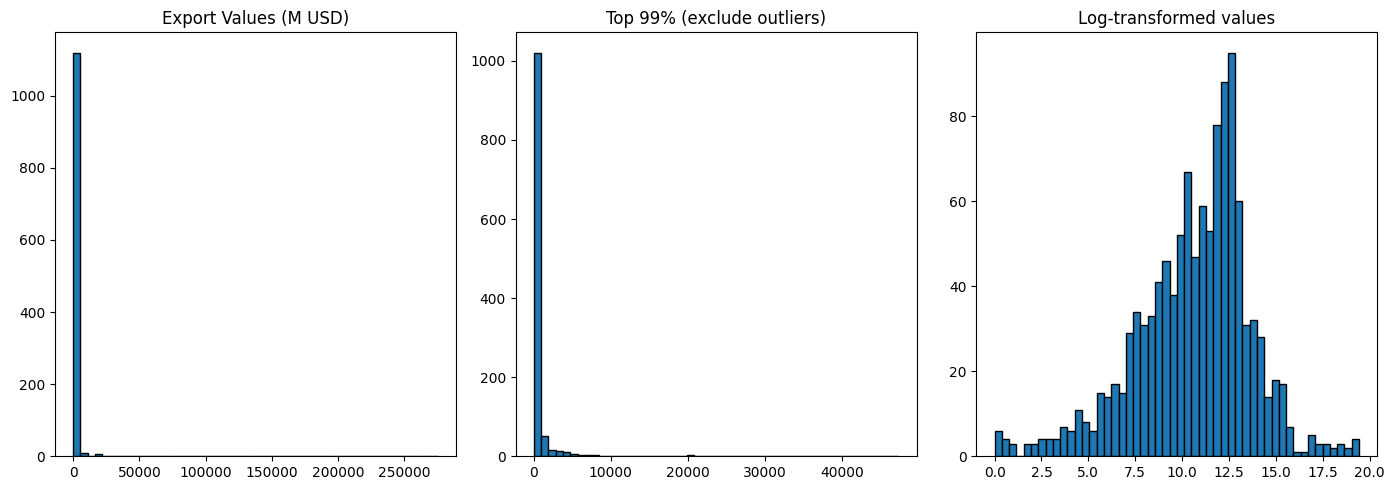


DATA QUALITY CHECK:
Zero export rows: 4
HS chapters: 96


In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Copy the aggregated data
prod2 = prod.copy()

# Convert to millions USD for readability
prod2['Export_MUSD'] = prod2['Export_kUSD'] / 1000

print("\nBASIC STATISTICS (Million USD):")
print("Min:", prod2['Export_MUSD'].min())
print("Max:", prod2['Export_MUSD'].max())
print("Mean:", prod2['Export_MUSD'].mean())
print("Median:", prod2['Export_MUSD'].median())

# Percentiles
print("\nPERCENTILES:")
for p in [0, 25, 50, 75, 90, 95, 99, 99.5, 99.9, 100]:
    print(f"{p}%:", np.percentile(prod2['Export_MUSD'], p))

# Plot distribution
plt.figure(figsize=(14,5))

plt.subplot(1,3,1)
plt.hist(prod2['Export_MUSD'], bins=50, edgecolor='black')
plt.title("Export Values (M USD)")

plt.subplot(1,3,2)
p99 = np.percentile(prod2['Export_MUSD'], 99)
plt.hist(prod2[prod2['Export_MUSD'] <= p99]['Export_MUSD'], bins=50, edgecolor='black')
plt.title("Top 99% (exclude outliers)")

plt.subplot(1,3,3)
plt.hist(np.log1p(prod2['Export_kUSD']), bins=50, edgecolor='black')
plt.title("Log-transformed values")

plt.tight_layout()
plt.show()

print("\nDATA QUALITY CHECK:")
print("Zero export rows:", (prod2['Export_kUSD'] == 0).sum())
print("HS chapters:", prod2['ProductCode'].nunique())


In [4]:
# STEP 4 — Remove HS 27 (Mineral Fuels) — Outlier Removal

prod_no27 = prod[prod['ProductCode'] != '27'].copy()

print("Original rows:", len(prod))
print("After removing HS 27:", len(prod_no27))
print("Rows removed:", len(prod) - len(prod_no27))

print("HS chapters remaining:", prod_no27['ProductCode'].nunique())


Original rows: 1152
After removing HS 27: 1140
Rows removed: 12
HS chapters remaining: 95


NEW BASIC STATISTICS (M USD):
Min: 0.0
Max: 54752.104236
Mean: 642.2349726105263
Median: 61.270497500000005

PERCENTILES WITHOUT HS 27:
0%: 0.0
25%: 6.729663749999999
50%: 61.270497500000005
75%: 283.0291015
90%: 980.5778901000003
95%: 2366.2433660999945
99%: 10608.652060269578
99.5%: 21228.50394504005
99.9%: 39581.53596867826
100%: 54752.104236


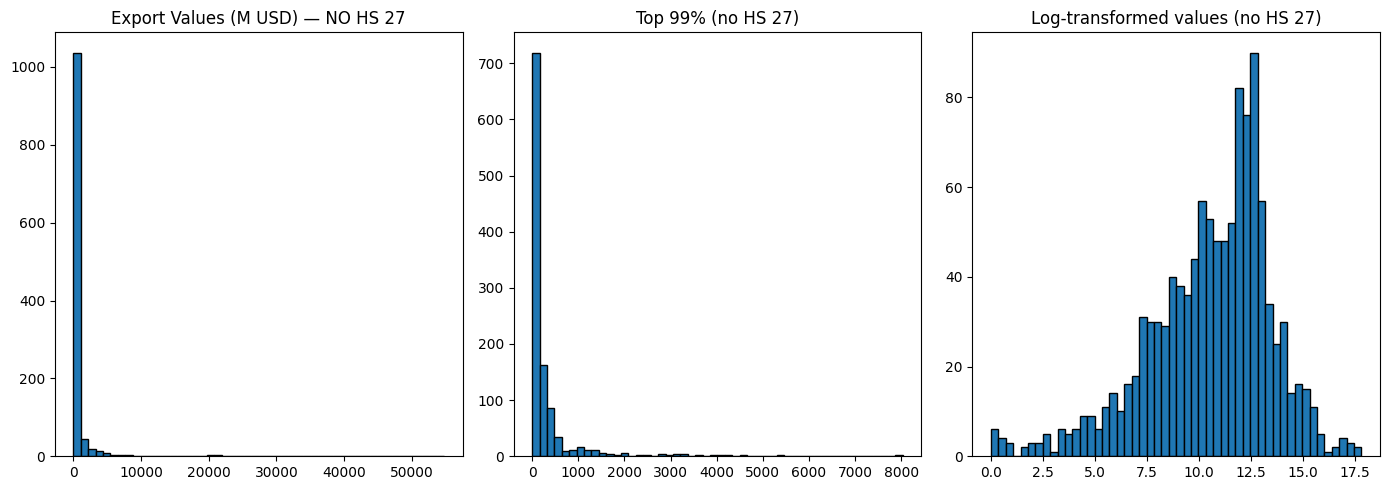

In [5]:
# STEP 5 — Recalculate statistics WITHOUT HS 27

prod_clean = prod_no27.copy()
prod_clean['Export_MUSD'] = prod_clean['Export_kUSD'] / 1000

print("NEW BASIC STATISTICS (M USD):")
print("Min:", prod_clean['Export_MUSD'].min())
print("Max:", prod_clean['Export_MUSD'].max())
print("Mean:", prod_clean['Export_MUSD'].mean())
print("Median:", prod_clean['Export_MUSD'].median())

# Percentiles again
print("\nPERCENTILES WITHOUT HS 27:")
for p in [0, 25, 50, 75, 90, 95, 99, 99.5, 99.9, 100]:
    print(f"{p}%:", np.percentile(prod_clean['Export_MUSD'], p))

# Histogram
plt.figure(figsize=(14,5))

plt.subplot(1,3,1)
plt.hist(prod_clean['Export_MUSD'], bins=50, edgecolor='black')
plt.title("Export Values (M USD) — NO HS 27")

plt.subplot(1,3,2)
p99 = np.percentile(prod_clean['Export_MUSD'], 99)
plt.hist(prod_clean[prod_clean['Export_MUSD'] <= p99]['Export_MUSD'], bins=50, edgecolor='black')
plt.title("Top 99% (no HS 27)")

plt.subplot(1,3,3)
plt.hist(np.log1p(prod_clean['Export_kUSD']), bins=50, edgecolor='black')
plt.title("Log-transformed values (no HS 27)")

plt.tight_layout()
plt.show()


In [6]:
# STEP 6 — Create Modeling Panel

panel_parts = []

# function to compute slope safely
def _safe_slope_last_k(values, k=3):
    values = pd.Series(values).dropna().values
    if len(values) < k:
        return 0.0
    y = values[-k:]
    x = np.arange(k, dtype=float)
    den = np.sum((x - x.mean())**2)
    if den == 0:
        return 0.0
    return np.sum((x - x.mean()) * (y - y.mean())) / den

# Build features for each HS-2 chapter
for code, sub in prod_clean.groupby('ProductCode'):

    g = sub.sort_values('Year').copy()

    # Lags
    g['Export_lag1'] = g['Export_kUSD'].shift(1)
    g['Export_lag2'] = g['Export_kUSD'].shift(2)

    # YoY growth
    prev = g['Export_lag1']
    g['YoY'] = (g['Export_kUSD'] / prev) - 1
    g.loc[prev == 0, 'YoY'] = 0

    # Rolling means & std
    g['Exp_roll_mean_3'] = g['Export_lag1'].rolling(3, min_periods=1).mean()
    g['Exp_roll_std_3'] = g['Export_lag1'].rolling(3, min_periods=1).std().fillna(0)

    # Rolling YoY
    g['YoY_roll_mean_3'] = g['YoY'].shift(1).rolling(3, min_periods=1).mean()
    g['YoY_roll_std_3'] = g['YoY'].shift(1).rolling(3, min_periods=1).std().fillna(0)

    # Drawdown: (lag1 / rolling max) - 1
    g['Exp_roll_max'] = g['Export_lag1'].rolling(5, min_periods=1).max()
    g['Drawdown'] = (g['Export_lag1'] / g['Exp_roll_max']) - 1
    g.loc[g['Exp_roll_max'] == 0, 'Drawdown'] = 0

    # Trend Slope
    g['Trend_slope_3'] = g['Export_lag1'].rolling(3).apply(
        lambda w: _safe_slope_last_k(w, 3), raw=False
    )

    # Size bucket
    g['Size_bucket'] = g['Exp_roll_mean_3'].rank(pct=True).apply(
        lambda x: np.floor(x * 3).clip(0,2)
    )

    # Target variable
    g['Export_next_year'] = g['Export_kUSD'].shift(-1)

    panel_parts.append(g)

panel = pd.concat(panel_parts, ignore_index=True)

# Clean infinities
panel = panel.replace([np.inf, -np.inf], np.nan)

print("Panel shape:", panel.shape)
panel.head(15)


Panel shape: (1140, 17)


,ProductCode,Year,Export_kUSD,ProductDescription,Export_MUSD,Export_lag1,Export_lag2,YoY,Exp_roll_mean_3,Exp_roll_std_3,YoY_roll_mean_3,YoY_roll_std_3,Exp_roll_max,Drawdown,Trend_slope_3,Size_bucket,Export_next_year
0,01,2012,15026.289,LIVE ANIMALS,15.026289,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000,NaN,NaN,NaN,NaN,26848.269
1,01,2013,26848.269,LIVE ANIMALS,26.848269,15026.289,NaN,0.786753,15026.289000,0.000000,NaN,0.000000,15026.289,0.000000,NaN,0.0,32484.459
2,01,2014,32484.459,LIVE ANIMALS,32.484459,26848.269,15026.289,0.209928,20937.279000,8359.402225,0.786753,0.000000,26848.269,0.000000,NaN,0.0,36823.115
3,01,2015,36823.115,LIVE ANIMALS,36.823115,32484.459,26848.269,0.133561,24786.339000,8909.859226,0.498340,0.407877,32484.459,0.000000,8729.0850,1.0,27364.859
4,01,2016,27364.859,LIVE ANIMALS,27.364859,36823.115,32484.459,-0.256856,32051.947667,5001.468556,0.376747,0.357123,36823.115,0.000000,4987.4230,2.0,19020.032
5,01,2017,19020.032,LIVE ANIMALS,19.020032,27364.859,36823.115,-0.304947,32224.144333,4734.498330,0.028877,0.250381,36823.115,-0.256856,-2559.8000,2.0,26472.723
6,01,2018,26472.723,LIVE ANIMALS,26.472723,19020.032,27364.859,0.391834,27736.002000,8907.342557,-0.142747,0.240495,36823.115,-0.483476,-8901.5415,1.0,32919.923
7,01,2019,32919.923,LIVE ANIMALS,32.919923,26472.723,19020.032,0.243541,24285.871333,4582.114640,-0.056657,0.389148,36823.115,-0.281084,-446.0680,0.0,32509.045
8,01,2020,32509.045,LIVE ANIMALS,32.509045,32919.923,26472.723,-0.012481,26137.559333,6956.004131,0.110143,0.367045,36823.115,-0.105998,6949.9455,1.0,21575.559
9,01,2021,21575.559,LIVE ANIMALS,21.575559,32509.045,32919.923,-0.336321,30633.897000,3609.533485,0.207631,0.204536,32919.923,-0.012481,3018.1610,2.0,31625.341


In [7]:
# ==========================================
# STEP 7: Define target + compare models
# Target: next-year export (log-transformed)
# ==========================================

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# If you have xgboost installed:
from xgboost import XGBRegressor

# -----------------------------
# 1. Define features and target
# -----------------------------

feature_names = [
    'Export_kUSD', 'Export_lag1', 'Export_lag2',
    'YoY', 'YoY_roll_mean_3', 'YoY_roll_std_3',
    'Exp_roll_mean_3', 'Exp_roll_std_3',
    'Drawdown', 'Trend_slope_3', 'Size_bucket'
]

panel_model = panel.copy()

# Log-transform target and current export
panel_model['Export_kUSD_log'] = np.log1p(panel_model['Export_kUSD'])
panel_model['Export_next_year_log'] = np.log1p(panel_model['Export_next_year'])

# Keep rows where target is known (we can't train on last year)
mask_target = panel_model['Export_next_year_log'].notna()

X_all = panel_model[feature_names].fillna(0.0)
y_all = panel_model['Export_next_year_log']

X_all = X_all[mask_target]
y_all = y_all[mask_target]
years_all = panel_model.loc[mask_target, 'Year']

# ---------------------------------
# 2. Time-based split (train/val/test)
# ---------------------------------

years_sorted = sorted(years_all.unique())

nY = len(years_sorted)
i_train_end = int(0.6 * nY)
i_valid_end = int(0.8 * nY)

train_years = years_sorted[:i_train_end]
valid_years = years_sorted[i_train_end:i_valid_end]
test_years  = years_sorted[i_valid_end:]

def mask_by_years(years_series, year_list):
    return years_series.isin(year_list).values

train_mask = mask_by_years(years_all, train_years)
valid_mask = mask_by_years(years_all, valid_years)
test_mask  = mask_by_years(years_all, test_years)

X_train, y_train = X_all[train_mask], y_all[train_mask]
X_valid, y_valid = X_all[valid_mask], y_all[valid_mask]
X_test,  y_test  = X_all[test_mask],  y_all[test_mask]

print("YEARS SPLIT:")
print("  Train years:", train_years)
print("  Valid years:", valid_years)
print("  Test years :", test_years)
print("Train samples:", X_train.shape[0],
      "| Valid samples:", X_valid.shape[0],
      "| Test samples:", X_test.shape[0])

# ---------------------------------
# 3. Helper: evaluation function
# ---------------------------------

def eval_on_original_scale(y_true_log, y_pred_log, label=""):
    """Evaluate metrics after converting log1p back to original kUSD scale."""
    y_true = np.expm1(y_true_log)
    y_pred = np.expm1(y_pred_log)
    r2 = r2_score(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    print(f"{label:25s} | R²={r2:6.3f}, RMSE={rmse:12,.0f} kUSD, MAE={mae:10,.0f} kUSD")
    return r2, rmse, mae

# ---------------------------------
# 4. Baseline models on test set
# ---------------------------------

panel_sub = panel_model[mask_target].copy()

baseline_naive_test_true_log = panel_sub.loc[test_mask, 'Export_next_year_log']
baseline_naive_test_pred_log = panel_sub.loc[test_mask, 'Export_kUSD_log']

baseline_ma3_test_pred = panel_sub.loc[test_mask, 'Exp_roll_mean_3'].fillna(
    panel_sub.loc[test_mask, 'Export_kUSD']
)
baseline_ma3_test_pred_log = np.log1p(baseline_ma3_test_pred)
baseline_ma3_test_true_log = baseline_naive_test_true_log

print("\nBASELINE PERFORMANCE (TEST SET):")
eval_on_original_scale(baseline_naive_test_true_log, baseline_naive_test_pred_log, "Naive (y_{t+1}=y_t)")
eval_on_original_scale(baseline_ma3_test_true_log,    baseline_ma3_test_pred_log,  "MA(3) baseline")

# ---------------------------------
# 5. Machine learning models to compare
# ---------------------------------

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=20,
        min_samples_leaf=1,
        max_features=0.7,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=300,
        max_depth=3,
        random_state=42
    ),
    "XGBoost": XGBRegressor(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbosity=0
    )
}

results = []

print("\nML MODEL PERFORMANCE (log-target, original-scale metrics):")

for name, model in models.items():
    model.fit(X_train, y_train)

    y_valid_pred_log = model.predict(X_valid)
    y_test_pred_log  = model.predict(X_test)

    print("-" * 80)
    print(f"Model: {name}")
    r2_v, rmse_v, mae_v = eval_on_original_scale(y_valid, y_valid_pred_log, "  Validation")
    r2_t, rmse_t, mae_t = eval_on_original_scale(y_test,  y_test_pred_log,  "  Test      ")

    results.append({
        "Model": name,
        "R2_valid": r2_v,
        "R2_test": r2_t,
        "RMSE_test_kUSD": rmse_t,
        "MAE_test_kUSD": mae_t
    })

results_df = pd.DataFrame(results).sort_values("R2_test", ascending=False)
print("\nSUMMARY (sorted by Test R²):")
print(results_df.to_string(index=False))


YEARS SPLIT:
  Train years: [np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017)]
  Valid years: [np.int64(2018), np.int64(2019)]
  Test years : [np.int64(2020), np.int64(2021), np.int64(2022)]
Train samples: 570 | Valid samples: 190 | Test samples: 285

BASELINE PERFORMANCE (TEST SET):
Naive (y_{t+1}=y_t)       | R²= 0.951, RMSE=   1,040,976 kUSD, MAE=   203,367 kUSD
MA(3) baseline            | R²= 0.787, RMSE=   2,164,225 kUSD, MAE=   410,236 kUSD

ML MODEL PERFORMANCE (log-target, original-scale metrics):
--------------------------------------------------------------------------------
Model: Random Forest
  Validation              | R²= 0.812, RMSE=   1,202,339 kUSD, MAE=   214,257 kUSD
  Test                    | R²= 0.566, RMSE=   3,091,932 kUSD, MAE=   479,735 kUSD
--------------------------------------------------------------------------------
Model: Gradient Boosting
  Validation              | R²= 0.872, RMSE=     993,128 kUSD, MAE=  

In [ ]:
import pandas as pd

# After collecting results in the loop
results_df = pd.DataFrame(results)

# Sort by Test R² for clarity
results_df = results_df.sort_values("R2_test", ascending=False).reset_index(drop=True)

# Display as a proper table
print("\nSUMMARY (sorted by Test R²):")
display(results_df.style.format({
    "R2_valid": "{:.3f}",
    "R2_test": "{:.3f}",
    "RMSE_test_kUSD": "{:,.0f}",
    "MAE_test_kUSD": "{:,.0f}"
}).set_table_styles([
    {"selector": "th", "props": [("background-color", "#004d4d"), ("color", "white")]},
    {"selector": "td", "props": [("background-color", "#f2f2f2")]}
]))



SUMMARY (sorted by Test R²):


,Model,R2_valid,R2_test,RMSE_test_kUSD,MAE_test_kUSD
0,Gradient Boosting,0.872,0.678,"2,661,213","428,237"
1,Random Forest,0.812,0.566,"3,091,932","479,735"
2,XGBoost,0.852,0.470,"3,414,156","493,400"


In [8]:
# ==========================================
# STEP 8 — Final predictions using best model
# Best model: Gradient Boosting Regressor
# ==========================================

from sklearn.ensemble import GradientBoostingRegressor

# 1. Prepare full training data (2012–2022)
panel_pred = panel.copy()

mask_train_full = panel_pred['Export_next_year'].notna()  # 2012–2022 only

X_full = panel_pred.loc[mask_train_full, feature_names].fillna(0.0)
y_full = np.log1p(panel_pred.loc[mask_train_full, 'Export_next_year'])

# 2. Train Gradient Boosting on full history
best_model = GradientBoostingRegressor(
    n_estimators=300,
    max_depth=3,
    random_state=42
)

best_model.fit(X_full, y_full)

print("Model trained on full history (2012–2022).")

# ====================================================
# 3. Predict exports for the next year (2023)
# ====================================================

# Select rows where Year = 2022 (we predict 2023 for each HS-2)
panel_2022 = panel_pred[panel_pred['Year'] == 2022].copy()

X_2022 = panel_2022[feature_names].fillna(0.0)

# Predict log target → convert back to USD
pred_log = best_model.predict(X_2022)
pred_exports = np.expm1(pred_log)  # convert log back to kUSD

panel_2022['Predicted_Export_2023_kUSD'] = pred_exports

# ====================================================
# 4. Compute growth rate from 2022 → 2023
# ====================================================

panel_2022['Growth_rate'] = (
    panel_2022['Predicted_Export_2023_kUSD'] - panel_2022['Export_kUSD']
) / panel_2022['Export_kUSD']

# ====================================================
# 5. Rank HS chapters by growth
# ====================================================

ranked = (
    panel_2022[['ProductCode', 'ProductDescription',
                'Export_kUSD', 'Predicted_Export_2023_kUSD', 'Growth_rate']]
    .sort_values('Growth_rate', ascending=False)
    .reset_index(drop=True)
)

print("\nTOP 10 FASTEST-GROWING HS CHAPTERS (Predicted 2023):")
print(ranked.head(10).to_string(index=False))

print("\nBOTTOM 10 (Declining sectors):")
print(ranked.tail(10).to_string(index=False))
panel_2022.to_csv('Predicted_Exports_2023.csv', index=False)

Model trained on full history (2012–2022).

TOP 10 FASTEST-GROWING HS CHAPTERS (Predicted 2023):
ProductCode                  ProductDescription  Export_kUSD  Predicted_Export_2023_kUSD  Growth_rate
         60        KNITTED OR CROCHETED FABRICS      878.849                1.767776e+03     1.011467
         41 RAW HIDES AND SKINS (OTHER THAN FUR     1463.662                2.881880e+03     0.968952
         45           CORK AND ARTICLES OF CORK     1774.668                2.696043e+03     0.519181
         80            TIN AND ARTICLES THEREOF    19403.403                2.841630e+04     0.464501
         65          HEADGEAR AND PARTS THEREOF     1843.245                2.610832e+03     0.416432
         52                              COTTON     2101.338                2.944861e+03     0.401422
         17      SUGARS AND SUGAR CONFECTIONERY   412316.331                5.515894e+05     0.337782
         89 SHIPS, BOATS AND FLOATING STRUCTURE   188350.456                2.491133e+0

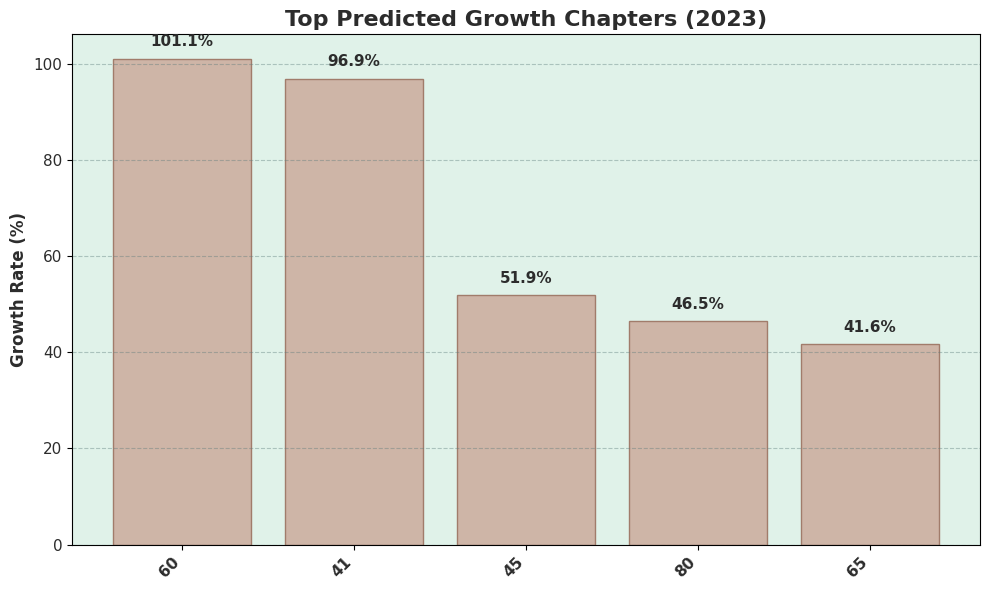

In [10]:
import matplotlib.pyplot as plt

# Select top 5 fastest-growing HS chapters dynamically
ranked_top5 = ranked.head(5)

# Extract product codes and growth rates
chapters = ranked_top5['ProductCode']
growth_rates = ranked_top5['Growth_rate'] * 100  # convert to %

# Refined palette
background_color = '#E0F2E9'   # soft mint background
bar_color = '#CEB5A7'          # warm beige bars
text_color = '#2C2C2C'         # dark charcoal for strong contrast
highlight_color = '#A17C6B'    # earthy brown accent for emphasis
grid_color = '#5B7B7A'         # muted teal for gridlines

plt.figure(figsize=(10,6))
bars = plt.bar(chapters, growth_rates, color=bar_color, edgecolor=highlight_color)

# Add percentage labels above bars
for bar, rate in zip(bars, growth_rates):
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 2,
             f"{rate:.1f}%",
             ha='center', va='bottom', fontsize=11, fontweight='bold', color=text_color)

# Styling
plt.title("Top Predicted Growth Chapters (2023)", fontsize=16, fontweight='bold', color=text_color)
plt.ylabel("Growth Rate (%)", fontsize=12, fontweight='bold', color=text_color)
plt.xticks(rotation=45, ha='right', fontsize=11, fontweight='bold', color=text_color)
plt.yticks(fontsize=11, color=text_color)
plt.grid(axis='y', linestyle='--', alpha=0.4, color=grid_color)
plt.gca().set_facecolor(background_color)

plt.tight_layout()
plt.show()

In [ ]:
import joblib

# 1) Save the trained Gradient Boosting model
joblib.dump(best_model, "uae_gb_non_oil_exports_model.joblib")

# 2) Save the feature list used during training
joblib.dump(feature_names, "uae_gb_feature_names.joblib")

print("✅ Model and feature names saved!")


✅ Model and feature names saved!


In [ ]:
import numpy as np
import pandas as pd
import joblib

# Load model + feature names
gb_model = joblib.load("uae_gb_non_oil_exports_model.joblib")
feature_names = joblib.load("uae_gb_feature_names.joblib")

print("✅ Model and features loaded!")
print("Features:", feature_names)


✅ Model and features loaded!
Features: ['Export_kUSD', 'Export_lag1', 'Export_lag2', 'YoY', 'YoY_roll_mean_3', 'YoY_roll_std_3', 'Exp_roll_mean_3', 'Exp_roll_std_3', 'Drawdown', 'Trend_slope_3', 'Size_bucket']


In [ ]:
import numpy as np
import pandas as pd
import joblib

# 1. Load model + features
gb_model = joblib.load("uae_gb_non_oil_exports_model.joblib")
feature_names = joblib.load("uae_gb_feature_names.joblib")

print("✅ Model and features loaded for deployment")


# 2. Helper: build features from a simple export history list
def _safe_slope_last_k(values, k=3):
    values = pd.Series(values).dropna().values
    if len(values) < k:
        return 0.0
    y = values[-k:]
    x = np.arange(k, dtype=float)
    den = np.sum((x - x.mean())**2)
    if den == 0:
        return 0.0
    return np.sum((x - x.mean()) * (y - y.mean())) / den


def build_features_from_history(export_history_kusd):
    """
    export_history_kusd: list of exports (in 1000 USD), ordered by year: [y1, y2, ..., yT]
    Returns a single-row DataFrame with the feature columns expected by the model.
    """
    s = pd.Series(export_history_kusd, dtype=float)
    feat = {col: 0.0 for col in feature_names}

    # current and lags
    feat["Export_kUSD"]   = s.iloc[-1] if len(s) >= 1 else 0.0
    feat["Export_lag1"]   = s.iloc[-2] if len(s) >= 2 else 0.0
    feat["Export_lag2"]   = s.iloc[-3] if len(s) >= 3 else 0.0

    # YoY
    prev = feat["Export_lag1"]
    if prev > 0:
        feat["YoY"] = feat["Export_kUSD"] / prev - 1.0
    else:
        feat["YoY"] = 0.0

    # rolling on lagged values
    lagged = s.iloc[:-1] if len(s) > 1 else s
    last3 = lagged.tail(3)
    feat["Exp_roll_mean_3"] = last3.mean() if len(last3) > 0 else 0.0
    feat["Exp_roll_std_3"]  = last3.std()  if len(last3) > 1 else 0.0

    # YoY rolling
    yoy_series = (lagged / lagged.shift(1) - 1).dropna()
    last3_yoy = yoy_series.tail(3)
    feat["YoY_roll_mean_3"] = last3_yoy.mean() if len(last3_yoy) > 0 else 0.0
    feat["YoY_roll_std_3"]  = last3_yoy.std()  if len(last3_yoy) > 1 else 0.0

    # Drawdown vs rolling max of last 5 lags
    last5 = lagged.tail(5)
    rolling_max = last5.max() if len(last5) > 0 else 0.0
    if rolling_max > 0 and feat["Export_lag1"] > 0:
        feat["Drawdown"] = feat["Export_lag1"] / rolling_max - 1.0
    else:
        feat["Drawdown"] = 0.0

    # Trend slope of last 3 lagged values
    feat["Trend_slope_3"] = _safe_slope_last_k(last3.tolist(), 3) if len(last3) >= 3 else 0.0

    # Size bucket (simple heuristic)
    mean_val = feat["Exp_roll_mean_3"]
    if mean_val < 100000:      # < 100M
        feat["Size_bucket"] = 1
    elif mean_val < 1000000:   # 100M–1B
        feat["Size_bucket"] = 2
    else:
        feat["Size_bucket"] = 0

    # return as DataFrame with the correct column order
    return pd.DataFrame([feat])[feature_names]


# 3. Main prediction function
def predict_next_year_export(export_history_kusd):
    """
    Input: list of exports in 1000 USD, oldest → newest, for a single HS chapter.
    Output: dict with predicted next-year exports and growth rate.
    """
    if len(export_history_kusd) < 3:
        raise ValueError("Please provide at least 3 years of export history.")

    X = build_features_from_history(export_history_kusd)
    pred_log = gb_model.predict(X)[0]
    pred_kusd = np.expm1(pred_log)

    current_kusd = export_history_kusd[-1]
    growth_rate = (pred_kusd - current_kusd) / current_kusd if current_kusd > 0 else 0.0

    return {
        "current_export_kUSD": current_kusd,
        "predicted_next_year_kUSD": pred_kusd,
        "predicted_growth_rate": growth_rate
    }


# 4. Example usage
example_history = [50000, 62000, 71000, 83000, 90000]  # in 1000 USD
result = predict_next_year_export(example_history)

print("\nExample prediction:")
print(f"Current export: {result['current_export_kUSD']:,.0f} kUSD")
print(f"Predicted next year: {result['predicted_next_year_kUSD']:,.0f} kUSD")
print(f"Predicted growth: {result['predicted_growth_rate']*100:,.1f}%")


✅ Model and features loaded for deployment

Example prediction:
Current export: 90,000 kUSD
Predicted next year: 91,331 kUSD
Predicted growth: 1.5%


In [ ]:
# uae_export_predict_cli.py

import numpy as np
import pandas as pd
import joblib

# ============================================
# 1. Load trained model and feature names
# ============================================

gb_model = joblib.load("uae_gb_non_oil_exports_model.joblib")
feature_names = joblib.load("uae_gb_feature_names.joblib")

print("✅ UAE Export Growth Model loaded successfully!")
print("Features used by the model:", feature_names)


# ============================================
# 2. Helper functions for feature engineering
# ============================================

def _safe_slope_last_k(values, k=3):
    values = pd.Series(values).dropna().values
    if len(values) < k:
        return 0.0
    y = values[-k:]
    x = np.arange(k, dtype=float)
    den = np.sum((x - x.mean())**2)
    if den == 0:
        return 0.0
    return np.sum((x - x.mean()) * (y - y.mean())) / den


def build_features_from_history(export_history_kusd):
    s = pd.Series(export_history_kusd, dtype=float)
    feat = {col: 0.0 for col in feature_names}

    feat["Export_kUSD"] = s.iloc[-1] if len(s) >= 1 else 0.0
    feat["Export_lag1"] = s.iloc[-2] if len(s) >= 2 else 0.0
    feat["Export_lag2"] = s.iloc[-3] if len(s) >= 3 else 0.0

    prev = feat["Export_lag1"]
    feat["YoY"] = feat["Export_kUSD"] / prev - 1.0 if prev > 0 else 0.0

    lagged = s.iloc[:-1] if len(s) > 1 else s
    last3 = lagged.tail(3)
    feat["Exp_roll_mean_3"] = last3.mean() if len(last3) > 0 else 0.0
    feat["Exp_roll_std_3"]  = last3.std()  if len(last3) > 1 else 0.0

    yoy_series = (lagged / lagged.shift(1) - 1).dropna()
    last3_yoy = yoy_series.tail(3)
    feat["YoY_roll_mean_3"] = last3_yoy.mean() if len(last3_yoy) > 0 else 0.0
    feat["YoY_roll_std_3"]  = last3_yoy.std()  if len(last3_yoy) > 1 else 0.0

    last5 = lagged.tail(5)
    rolling_max = last5.max() if len(last5) > 0 else 0.0
    feat["Drawdown"] = feat["Export_lag1"] / rolling_max - 1.0 if rolling_max > 0 and feat["Export_lag1"] > 0 else 0.0

    feat["Trend_slope_3"] = _safe_slope_last_k(last3.tolist(), 3) if len(last3) >= 3 else 0.0

    mean_val = feat["Exp_roll_mean_3"]
    if mean_val < 100_000:
        feat["Size_bucket"] = 1
    elif mean_val < 1_000_000:
        feat["Size_bucket"] = 2
    else:
        feat["Size_bucket"] = 0

    return pd.DataFrame([feat])[feature_names]


def predict_next_year_export(export_history_kusd):
    if len(export_history_kusd) < 3:
        raise ValueError("Please provide at least 3 years of export history (in 1000 USD).")

    X = build_features_from_history(export_history_kusd)
    pred_log = gb_model.predict(X)[0]
    pred_kusd = np.expm1(pred_log)

    current_kusd = export_history_kusd[-1]
    growth_rate = (pred_kusd - current_kusd) / current_kusd if current_kusd > 0 else 0.0

    return {
        "current_export_kUSD": current_kusd,
        "predicted_next_year_kUSD": pred_kusd,
        "predicted_growth_rate": growth_rate
    }


# ============================================
# 3. Interactive CLI – with automatic year labels
# ============================================

if __name__ == "__main__":
    print("\n==============================================")
    print(" 🇦🇪 UAE NON-OIL EXPORT GROWTH PREDICTOR (CLI)")
    print("==============================================\n")

    hs_code = input("Enter HS-2 Chapter Code (e.g., 60, 33, 89): ").strip()
    if hs_code == "":
        hs_code = "Unknown"

    while True:
        try:
            num_years = int(input("How many years of export history do you have? (min 3, max 12): "))
            if 3 <= num_years <= 12:
                break
            else:
                print("Please enter a number between 3 and 12.")
        except ValueError:
            print("Please enter a valid integer.")

    # Accept any year for the last year
    while True:
        try:
            last_year = int(input("Enter the last year of your history: "))
            break
        except ValueError:
            print("Please enter a valid year, e.g., 2023.")

    years_list = list(range(last_year - num_years + 1, last_year + 1))

    print("\nPlease enter export values in 1000 USD (oldest year first, latest year last).")
    history = []
    for year in years_list:
        while True:
            try:
                val = float(input(f"  Export value for {year} (in 1000 USD): "))
                history.append(val)
                break
            except ValueError:
                print("  Invalid input, please enter a number (e.g., 12345.67).")

    try:
        result = predict_next_year_export(history)
        next_year = last_year + 1

        print("\n==================== PREDICTION RESULT ====================")
        print(f"HS Chapter: {hs_code}")
        print(f"Current export ({last_year}): {result['current_export_kUSD']:,.0f} kUSD")
        print(f"Predicted export ({next_year}): {result['predicted_next_year_kUSD']:,.0f} kUSD")
        print(f"Predicted growth rate: {result['predicted_growth_rate']*100:,.2f}%")

        if result['predicted_growth_rate'] > 0.4:
            print("Growth Category: HIGH GROWTH 🚀")
        elif result['predicted_growth_rate'] > 0.1:
            print("Growth Category: MODERATE GROWTH 📈")
        elif result['predicted_growth_rate'] > 0:
            print("Growth Category: SLOW GROWTH ↗")
        else:
            print("Growth Category: STABLE / DECLINING ➡")
        print("===========================================================\n")

    except Exception as e:
        print("\n❌ Error during prediction:", e)
        print("Please check your inputs and try again.")


✅ UAE Export Growth Model loaded successfully!
Features used by the model: ['Export_kUSD', 'Export_lag1', 'Export_lag2', 'YoY', 'YoY_roll_mean_3', 'YoY_roll_std_3', 'Exp_roll_mean_3', 'Exp_roll_std_3', 'Drawdown', 'Trend_slope_3', 'Size_bucket']

 🇦🇪 UAE NON-OIL EXPORT GROWTH PREDICTOR (CLI)

Enter HS-2 Chapter Code (e.g., 60, 33, 89): 25
How many years of export history do you have? (min 3, max 12): 3
Enter the last year of your history: 2020

Please enter export values in 1000 USD (oldest year first, latest year last).
  Export value for 2018 (in 1000 USD): 2340
  Export value for 2019 (in 1000 USD): 2508
  Export value for 2020 (in 1000 USD): 3000

==================== PREDICTION RESULT ====================
HS Chapter: 25
Current export (2020): 3,000 kUSD
Predicted export (2021): 3,875 kUSD
Predicted growth rate: 29.17%
Growth Category: MODERATE GROWTH 📈



In [ ]:
# =====================================================
# FULLY AUTOMATIC STREAMLIT + NGROK DEPLOY (COLAB)
# =====================================================

import os, sys, subprocess, time, textwrap

# -------------------------------
# 1) Write the Streamlit app to app.py
# -------------------------------
app_code = textwrap.dedent(r"""
import numpy as np
import pandas as pd
import joblib
import streamlit as st

@st.cache_resource
def load_model():
    model = joblib.load("uae_gb_non_oil_exports_model.joblib")
    feature_names = joblib.load("uae_gb_feature_names.joblib")
    return model, feature_names

gb_model, feature_names = load_model()

def _safe_slope_last_k(values, k=3):
    values = pd.Series(values).dropna().values
    if len(values) < k:
        return 0.0
    y = values[-k:]
    x = np.arange(k, dtype=float)
    den = np.sum((x - x.mean())**2)
    if den == 0:
        return 0.0
    return np.sum((x - x.mean()) * (y - y.mean())) / den

def build_features_from_history(export_history_kusd, feature_names):
    s = pd.Series(export_history_kusd, dtype=float)
    feat = {col: 0.0 for col in feature_names}

    feat["Export_kUSD"] = s.iloc[-1]
    feat["Export_lag1"] = s.iloc[-2] if len(s) >= 2 else 0.0
    feat["Export_lag2"] = s.iloc[-3] if len(s) >= 3 else 0.0

    prev = feat["Export_lag1"]
    feat["YoY"] = feat["Export_kUSD"] / prev - 1.0 if prev > 0 else 0.0

    lagged = s.iloc[:-1] if len(s) > 1 else s
    last3 = lagged.tail(3)
    feat["Exp_roll_mean_3"] = last3.mean() if len(last3) > 0 else 0.0
    feat["Exp_roll_std_3"]  = last3.std()  if len(last3) > 1 else 0.0

    yoy_series = (lagged / lagged.shift(1) - 1).dropna()
    last3_yoy = yoy_series.tail(3)
    feat["YoY_roll_mean_3"] = last3_yoy.mean() if len(last3_yoy) > 0 else 0.0
    feat["YoY_roll_std_3"]  = last3_yoy.std()  if len(last3_yoy) > 1 else 0.0

    last5 = lagged.tail(5)
    rolling_max = last5.max() if len(last5) > 0 else 0.0
    feat["Drawdown"] = feat["Export_lag1"] / rolling_max - 1.0 if rolling_max > 0 else 0.0

    feat["Trend_slope_3"] = _safe_slope_last_k(last3.tolist(), 3) if len(last3) >= 3 else 0.0

    mean_val = feat["Exp_roll_mean_3"]
    if mean_val < 100_000:
        feat["Size_bucket"] = 1
    elif mean_val < 1_000_000:
        feat["Size_bucket"] = 2
    else:
        feat["Size_bucket"] = 0

    return pd.DataFrame([feat])[feature_names]

def predict_next_year_export(history, last_year):
    X = build_features_from_history(history, feature_names)
    pred_log = gb_model.predict(X)[0]
    pred_kusd = np.expm1(pred_log)

    current_kusd = history[-1]
    growth_rate = (pred_kusd - current_kusd) / current_kusd if current_kusd > 0 else 0.0
    next_year = last_year + 1

    return {
        "last_year": last_year,
        "next_year": next_year,
        "current_export_kUSD": current_kusd,
        "predicted_next_year_kUSD": pred_kusd,
        "predicted_growth_rate": growth_rate
    }

def growth_category(g):
    if g > 0.4:
        return "HIGH GROWTH 🚀"
    elif g > 0.1:
        return "MODERATE GROWTH 📈"
    elif g > 0:
        return "SLOW GROWTH ↗"
    else:
        return "STABLE / DECLINING ➡"

st.set_page_config(page_title="UAE Export Growth Predictor", page_icon="🇦🇪")

st.title("🇦🇪 UAE Non-Oil Export Growth Predictor")
st.write("Predict next-year export for a given HS-2 chapter using your trained Gradient Boosting model.")

hs_code = st.text_input("HS-2 Chapter Code (e.g., 25, 33, 60, 89)", value="25")
num_years = st.slider("Number of years of history", min_value=3, max_value=12, value=4)
last_year = st.number_input("Last year of your data", min_value=1900, max_value=2100, value=2023, step=1)

years_list = list(range(last_year - num_years + 1, last_year + 1))

st.markdown("### Export history (in 1000 USD)")
st.write("Enter export values for each year:")

history = []
cols = st.columns(4)
for i, year in enumerate(years_list):
    with cols[i % 4]:
        val = st.number_input(f"{year}", min_value=0.0, value=0.0, step=1000.0, key=f"exp_{year}")
        history.append(val)

if st.button("Predict next-year export"):
    try:
        if all(v == 0 for v in history):
            st.error("Please enter at least one non-zero export value.")
        else:
            result = predict_next_year_export(history, last_year)
            growth = result["predicted_growth_rate"]

            c1, c2 = st.columns(2)
            with c1:
                st.metric(
                    label=f"Current export ({result['last_year']})",
                    value=f"{result['current_export_kUSD']:,.0f} kUSD"
                )
            with c2:
                st.metric(
                    label=f"Predicted export ({result['next_year']})",
                    value=f"{result['predicted_next_year_kUSD']:,.0f} kUSD",
                    delta=f"{growth*100:,.2f}%"
                )

            st.write(f"### Growth Category: {growth_category(growth)}")

            st.markdown("#### Raw prediction data")
            st.json({
                "HS_chapter": hs_code,
                "last_year": int(result["last_year"]),
                "next_year": int(result["next_year"]),
                "current_export_kUSD": float(result["current_export_kUSD"]),
                "predicted_next_year_kUSD": float(result["predicted_next_year_kUSD"]),
                "predicted_growth_rate_percent": float(growth * 100.0)
            })
    except Exception as e:
        st.error(f"Error during prediction: {e}")
""")

with open("app.py", "w") as f:
    f.write(app_code)

print("✅ app.py written successfully.")

# -------------------------------
# 2) Install required packages
# -------------------------------
print("\n📦 Installing required libraries (this may take a bit)...")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "streamlit", "pyngrok", "joblib", "scikit-learn", "xgboost", "pandas", "numpy"])

print("✅ Libraries installed.")

# -------------------------------
# 3) Configure ngrok and start Streamlit
# -------------------------------
from pyngrok import ngrok

NGROK_TOKEN = "35qWeS38lQPOeTZ4qXnXdJWFhtA_sDfT9ng2p7keDC6prCfQ"  # <-- CHANGE THIS

if NGROK_TOKEN == "YOUR_NEW_NGROK_TOKEN_HERE":
    print("\n❌ Please edit the cell and set NGROK_TOKEN to your real token, then run again.")
else:
    ngrok.set_auth_token(NGROK_TOKEN)
    print("\n🔐 Ngrok auth token set.")

    ngrok.kill()

    print("\n🚀 Starting Streamlit app on port 8501...")
    streamlit_proc = subprocess.Popen(
        ["streamlit", "run", "app.py", "--server.port", "8501", "--server.address", "0.0.0.0"],
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True
    )

    time.sleep(8)

    print("🌐 Creating ngrok tunnel...")
    public_url = ngrok.connect(8501, "http").public_url
    print(f"\n✅ Public URL for your app: {public_url}\n")

    print("\n--- Streamlit logs (first 20 lines) ---")
    for _ in range(20):
        line = streamlit_proc.stdout.readline()
        if not line:
            break
        print(line, end="")
    print("\n---------------------------------------")


✅ app.py written successfully.

📦 Installing required libraries (this may take a bit)...
✅ Libraries installed.

🔐 Ngrok auth token set.

🚀 Starting Streamlit app on port 8501...
🌐 Creating ngrok tunnel...


PyngrokNgrokHTTPError: ngrok client exception, API returned 502: {"error_code":103,"status_code":502,"msg":"failed to start tunnel","details":{"err":"failed to start tunnel: The endpoint 'https://unejective-vulturelike-maudie.ngrok-free.dev' is already online. Either\n1. stop your existing endpoint first, or\n2. start both endpoints with `--pooling-enabled` to load balance between them.\r\n\r\nERR_NGROK_334\r\n"}}
